# PTM3D Tutorial 01 — A global lunar diurnal run

A self-contained walkthrough of PTM3D's smallest end-to-end example: one full
lunar day (a synodic month, 29.53 Earth days) of surface temperature over the
*entire* Moon on a coarse global mesh. It is the notebook counterpart of
[`docs/tutorials/02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md)
and the README ["Get started"](../../../README.md#get-started) walkthrough —
same config, same binary.

## What you'll learn

- How a PTM3D YAML config maps to a simulation (body, mesh, time span,
  thermophysical properties, output).
- How to run `ptm_thermal_sim` from Python and stream its progress.
- The on-disk output format (`statistics/*.bin`, per-timestep snapshots,
  `mesh.ply`), and how to read a whole run directory with one object,
  `ptm.Results`.
- How to make a temperature map, orthographic globe views, a diurnal
  temperature curve, and a day/night-contrast plot from that output — and
  how to choose a color scale that does not hide the field's structure.
- Why the lunar surface swings from ~385 K at noon to ~66 K before dawn, and
  why the drop is gradual rather than instant (thermal inertia).
- How to swap the smooth sphere for real LOLA global topography, and how
  much the resulting slopes change peak temperature — and where.

**Cost:** CPU-only, well under a minute, <1 GB RAM. The run is a 1280-face
icosphere with radiation exchange off (a convex sphere has no self-view), so
no GPU and no view-factor matrix are involved.

**Prerequisite:** the `ptm` Python package (`pip install -e .` from the
repository root), a built `ptm_thermal_sim` binary, and the Moon SPICE
kernels — see the repo README's
[**Get started**](../../../README.md#get-started) section (steps 0-3). The
next two cells check for all three and print the command that fixes each
one that is missing.

## 0. Environment check

Checks, in order: the Python version; the `ptm` package, which carries the
run reader, the engine launcher and the plotting used below and which brings
numpy, matplotlib and PyYAML with it; then the `ptm_thermal_sim` binary, the
config, and the SPICE kernels. Each failure names the command that fixes it.


In [1]:
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")
if sys.version_info < (3, 8):
    print(f"WARNING: PTM3D's Python layer needs Python >= 3.8 "
          f"(README 'Prerequisites' table); you have {sys.version_info}.")

try:
    import ptm
except ImportError:
    raise ImportError(
        "The `ptm` package is not importable. Install it from the repository "
        "root -- it brings numpy, matplotlib and PyYAML with it:\n"
        f"    {sys.executable} -m pip install -e .\n"
        "Then Kernel > Restart and re-run this cell.")

import matplotlib
import numpy as np
import yaml

print(f"ptm        {ptm.__version__}")
print(f"numpy      {np.__version__}")
print(f"matplotlib {matplotlib.__version__}")
print(f"PyYAML     {yaml.__version__}")

Python 3.8.18 (/Users/paha3326/anaconda3/envs/europa_viz/bin/python)


ptm        0.2.0
numpy      1.24.4
matplotlib 3.7.5
PyYAML     6.0.2


In [2]:
from pathlib import Path

from ptm import paths

REPO_ROOT = paths.find_repo_root(Path.cwd())
if REPO_ROOT is None:
    raise RuntimeError(
        "No PTM3D checkout above the current directory (one holding both "
        "CMakeLists.txt and examples/). Open this notebook from inside a "
        "clone, or set $PTM_ROOT.")

BINARY = paths.find_engine_executable("ptm_thermal_sim", search_roots=[REPO_ROOT])
CONFIG = REPO_ROOT / "examples" / "quickstart_moon_diurnal.yaml"
KERNEL = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"

checks = [
    (BINARY is not None, "build/bin/ptm_thermal_sim",
     "build it (README 'Get started' step 2, or INSTALL.md), or point "
     "$PTM_BUILD_DIR at an existing build"),
    (CONFIG.exists(), str(CONFIG), "is this a complete checkout?"),
    (KERNEL.exists(), "the Moon SPICE kernels (~44 MB)",
     "python3 scripts/fetch_kernels.py --bodies moon"),
]
for ok, what, _ in checks:
    print(("found   " if ok else "MISSING ") + what)
missing = [f"{what}: {fix}" for ok, what, fix in checks if not ok]
if missing:
    raise FileNotFoundError("Not ready --\n  " + "\n  ".join(missing))

print("\nRepo root:", REPO_ROOT)
print("Binary:   ", BINARY)

found   build/bin/ptm_thermal_sim
found   /Users/paha3326/Projects/ptm-ux5a/examples/quickstart_moon_diurnal.yaml
found   the Moon SPICE kernels (~44 MB)

Repo root: /Users/paha3326/Projects/ptm-ux5a
Binary:    /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim


## 1. The config file

[`examples/quickstart_moon_diurnal.yaml`](../../../examples/quickstart_moon_diurnal.yaml)
drives everything below. It is deliberately small — a "hello world" config,
not a production one.


In [3]:
config_text = CONFIG.read_text()
print(config_text)

# PTM3D quickstart: global Moon diurnal run on a small icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, < 1 GB RAM, minutes of wall time). All paths are
# relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies moon   # once, ~44 MB from NAIF
#     (the bare command also fetches the 1.1 GB Galilean ephemeris for europa.tm)
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_moon_diurnal.yaml
#
# Outputs land in output/quickstart_moon_diurnal/ (per-face statistics binaries).
# See docs/tutorials/ for a walkthrough of the outputs.

simulation:
  start_time: '2026-04-05T00:00:00'
  duration_days: 29.53          # one synodic lunar day
  timesteps: 240                # ~3 h output cadence
  body: Moon
mesh:
  resolution: 3                 # icosphere subdivision level (1280 faces)
  import_file: ''
  scale_factor: 1.0
  use_topographic: false
thermal:
  run_thermal_mesh: true
  threads: 0                

In [4]:
import json

cfg = yaml.safe_load(config_text)
print(json.dumps(cfg, indent=2))

{
  "simulation": {
    "start_time": "2026-04-05T00:00:00",
    "duration_days": 29.53,
    "timesteps": 240,
    "body": "Moon"
  },
  "mesh": {
    "resolution": 3,
    "import_file": "",
    "scale_factor": 1.0,
    "use_topographic": false
  },
  "thermal": {
    "run_thermal_mesh": true,
    "threads": 0,
    "equilibration_orbits": 1.0,
    "equilibration_steps_per_day": -1.0,
    "use_gpu": false,
    "compute_statistics": true,
    "enable_shadow_flux": false,
    "crater_dd_ratio": 8.0,
    "geothermal_heat_flow": -1.0
  },
  "thermophysical": {
    "use_default_albedo": true,
    "incidence_angle_albedo": true
  },
  "radiation": {
    "enabled": false
  },
  "illumination": {
    "include_primary_reflection": true,
    "use_batch_processing": true,
    "use_albedo_map": false,
    "albedo_maps_directory": "data/albedo_maps"
  },
  "output": {
    "directory": "output/quickstart_moon_diurnal",
    "format": "binary",
    "vtk_mode": "thermal"
  },
  "advanced": {
    "verbos

### Reading the blocks

- **`simulation`** — `body: Moon` selects PTM3D's built-in lunar ephemeris,
  radius, rotation, and default regolith thermal properties (no
  `generic_body:` block needed). `start_time` + `duration_days: 29.53` span
  exactly one synodic month; `timesteps: 240` sets the *output* cadence
  (~3 h/step). Separately, the thermal solver spins up for
  `thermal.equilibration_orbits: 1.0` extra lunation *before* the output
  window, so the reported statistics are free of start-up transients.

- **`mesh`** — `resolution: 3` is an icosphere subdivision level: level 0 is
  a 20-face icosahedron, and each level roughly quadruples the face count.
  Level 3 gives 1280 faces (~480 km face pitch) — coarse, so this runs in
  seconds. `use_topographic: false` means no DEM is loaded; every face sits
  on the mean lunar sphere.

- **`thermal`** — `run_thermal_mesh: true` turns on the 1D Crank-Nicolson
  conduction column under every face (vs. an illumination-only run).
  `threads: 0` auto-detects the OpenMP thread count; `use_gpu: false` keeps
  the run entirely on the CPU. `compute_statistics: true` writes the
  `statistics/*.bin` files this notebook reads in section 3.

- **`thermophysical`** — on a *built-in* body (`body: Moon`, as here) the
  parser reads only `use_default_albedo`, `incidence_angle_albedo`, and a
  short list of `*_override`/`*_model` keys. Plain-named properties
  (`albedo:`, `emissivity:`, `ks:`, `H:`) are not read on a named body — they
  are honored only under a custom `generic_body.surface:` block, and the
  engine warns if it finds them (see
  [`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)); this config
  omits them. With `use_default_albedo: true`, the Moon's Bond albedo (0.12)
  comes from the built-in default, confirmed in the run log
  ("`Default albedo: 0.120`"). `incidence_angle_albedo: true` means the
  *absorbed* flux uses a Hapke directional-hemispheric albedo
  $A_h(i) = 1-\gamma H(\mu_0,w)$ built from that Bond albedo, rather than a
  flat 0.12 at every incidence angle — the run log prints the corresponding
  line ("Using directional-hemispheric (Hapke) albedo ... single-scattering
  $w=0.496$").

- **`radiation.enabled: false`** — the Moon here is a smooth convex sphere:
  no face can ever see another face, so there is nothing for the
  view-factor / radiosity solver to do. See
  [`04_crater_radiosity.md`](../04_crater_radiosity.md) for a concave
  geometry where radiation exchange matters.

- **`output`** — `directory: output/quickstart_moon_diurnal`,
  `format: binary` (the compact `.bin` format this notebook parses below).
  Everything lands under `REPO_ROOT` regardless of where Jupyter was
  launched, because the run cell passes `cwd=REPO_ROOT` to the subprocess.


## 2. Run the simulation

**Expected wall time:** typically 5-8 s on a many-core workstation (longer if
the machine is busy), up to a couple of minutes on a 2-4 core laptop — it
threads over whatever cores are available. The cell prints the measured time
for your run.

The raw stdout mixes a fast (<1 s) percentage progress bar and an export
progress counter, both updated with carriage returns rather than newlines.
The cell below streams it live but **throttles the two progress readouts to
roughly every 25%** so the executed notebook stays readable; every
non-progress line (mesh size, thread count, final results) is shown in full.


In [5]:
import re
import time

from ptm import run as engine

STEP_RE = re.compile(r"Progress (\d+)/(\d+)")


def run_engine(config, extra_args=(), stream=True, show=()):
    """Run ptm_thermal_sim to completion; return (output lines, wall seconds).

    `stream=True` echoes the engine's output live, throttling its two
    carriage-return progress readouts to roughly every 25% so the executed
    notebook stays readable; every other line is shown in full. `stream=False`
    is quiet and prints only lines containing one of `show`, which is what the
    multi-run section 6 wants.
    """
    cmd = engine.build_command(BINARY, config) + list(extra_args)
    print("Running:", " ".join(str(c) for c in cmd), f"\n(cwd={REPO_ROOT})\n")
    out, seen = [], {"pct": -1.0, "step": -1}

    def take(line):
        out.append(line)
        if not stream:
            return
        pct, step = engine.extract_progress(line), STEP_RE.search(line)
        if pct is not None:
            if pct in (0.0, 100.0) or pct - seen["pct"] >= 25.0:
                print(line)
                seen["pct"] = pct
        elif step:
            done, total = int(step.group(1)), int(step.group(2))
            if done == total or done - seen["step"] >= max(total // 4, 1):
                print(line)
                seen["step"] = done
        else:
            print(line)

    t0 = time.time()
    rc = engine.EngineProcess(cmd, working_dir=REPO_ROOT, on_output=take,
                              on_warning=take, on_error=take).run()
    dt = time.time() - t0
    if rc != 0:
        raise RuntimeError(f"{config} exited with code {rc}:\n" + "\n".join(out[-30:]))
    for line in out:
        if any(k in line for k in show):
            print("   ", line.strip())
    if stream:
        print(f"\n--- {len(out)} raw output lines seen; wall time {dt:.1f} s; "
              f"exit code {rc} ---")
    else:
        print(f"    -> exit 0 in {dt:.1f} s")
    return out, dt


engine_output, wall_time_s = run_engine(CONFIG)

Running: /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-ux5a/examples/quickstart_moon_diurnal.yaml 
(cwd=/Users/paha3326/Projects/ptm-ux5a)



╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-ux5a/examples/quickstart_moon_diurnal.yaml
✓ Configuration loaded from: /Users/paha3326/Projects/ptm-ux5a/examples/quickstart_moon_diurnal.yaml
Hapke albedo gate: body single-scattering w = 0.496358 from Bond albedo A0 = 0.12 (per-face w supersedes at each flux site)
Usi

Calculating illumination:  [============>                                     ] 25% | elapsed 0s, ETA 0s
Calculating illumination:  [=========================>                        ] 50% | elapsed 0s, ETA 0s


Calculating illumination:  [=====================================>            ] 75% | elapsed 0s, ETA 0s
Calculating illumination:  [==================================================] 100% | elapsed 1s
Illumination calculation completed in 0.667 seconds.
Results:
Average total flux: 455.993377907 W/m^2
- Direct solar: 455.961074443 W/m^2
- Primary reflected: 0.010316377 W/m^2
- Primary IR: 0.021987088 W/m^2
Maximum total flux: 1381.280797944 W/m^2
- Direct solar: 1381.280797944 W/m^2
- Primary reflected: 0.085032703 W/m^2
- Primary IR: 0.075130142 W/m^2
Minimum flux (non-zero): 0.000000000 W/m^2
Ray tracing computation completed in 0.670 seconds (670 ms)
Verifying extracted illumination data:
Expected array size: 1280 * 480 = 614400
Illumination array size: 614400
Direct solar array size: 614400
Times array size: 480
[solar-const] incidence albedo uses the INSTANTANEOUS heliocentric solar constant (PTM-28 fix, default ON); S_inst range [1332.6, 1381.4] W/m^2
Non-zero illumination valu

SIMD Batch thermal [>                                                 ] 0% | elapsed 0s
SIMD Batch thermal [============>                                     ] 25% | elapsed 0s, ETA 0s
SIMD Batch thermal [=========================>                        ] 50% | elapsed 0s, ETA 0s
SIMD Batch thermal [=====================================>            ] 75% | elapsed 0s, ETA 0s
SIMD Batch thermal [==================================================] 100% | elapsed 0s
SIMD Batch thermal computation completed in 0.202 seconds (202 ms)
SIMD Batch thermal models completed successfully!
[Memory] Released combined illumination array (keeping per-component arrays for export)
[Integration] Statistics interval
Start (abs step): 240
Duration (steps): 240
Body positions written to output/quickstart_moon_diurnal/body_positions.csv
Using binary output format for data files
[exportDataAsBinary] Starting binary export
Faces=1280 time_steps=240 components: illumination direct_solar primary_reflected prim

Progress 61/240


Progress 121/240


Progress 181/240


Progress 240/240
Export complete: 240/240
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_moon_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 1280
Time steps: 240
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_moon_diurnal/statistics
[albedo] PTM-107(a) effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.154457 over 1280/1280 ever-lit faces; per-face -> output/quickstart_moon_diurnal/statistics/effective_albedo.bin (uint32 n + float32[1280], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [240,480) -- the same w

## 3. Output tour

```
output/quickstart_moon_diurnal/
├── mesh.ply              # the 1280-face icosphere; face order matches every .bin file
├── metadata.txt           # faces, time_steps, exported components
├── time_steps.txt         # per-step time stamp (SPICE ET + a UTC label column)
├── body_positions.csv     # Sun vector per output step
├── statistics/            # 16 files: {temperature,illumination,direct_solar,
│                           #   primary_reflected,primary_ir}_{min,avg,max}.bin
│                           #   + effective_albedo.bin, all reduced over the
│                           #   240-step *output* window only (equilibration excluded)
├── temperature/            # temperature_0000.bin .. temperature_0239.bin (per-step)
├── illumination/           #   total absorbed flux per step
├── direct_solar/           #   direct solar component
├── primary_reflected/      #   Earth-reflected sunlight
└── primary_ir/              #   Earth thermal IR
```

(No `indirect_solar/`/`indirect_ir/` here — those exist only on runs with
`radiation.enabled: true`; see
[`06_interpreting_outputs.md`](../06_interpreting_outputs.md).)

### Binary format

`ptm.Results` reads these: `run.stat(field, moment)` for a statistic,
`run.field(field, step)` for one output step. The layout is worth knowing
anyway, because it is what those calls check. Every `.bin` file (both
`statistics/*.bin` and the per-timestep snapshots) is:

| bytes | content |
|---|---|
| 0-3 | 4-byte little-endian face-count header `n` (`int32`; every value is non-negative, so reading it as `uint32` agrees byte-for-byte) |
| 4 .. 4+4n | `n × float32`, little-endian, one value per mesh face, in mesh-face order |

For this run every `statistics/*.bin` is exactly `4 + 4*1280 = 5124` bytes;
the reader checks this on every file it opens and raises rather than
returning a short array.


In [6]:
from ptm import Results

run = Results(REPO_ROOT / "output" / "quickstart_moon_diurnal")
lat, lon = run.lat, run.lon

print(run)
print(f"mesh.ply: {run.mesh['n_vertices']} vertices, {run.n_faces} faces, "
      f"coordinates in {run.mesh_units}")
print(f"  latitude  range [{lat.min():.1f}, {lat.max():.1f}] deg, "
      f"{len(np.unique(np.round(lat, 3)))} distinct values")
print(f"  longitude range [{lon.min():.1f}, {lon.max():.1f}] deg, "
      f"{len(np.unique(np.round(lon, 3)))} distinct values")
print("  (fewer distinct latitudes than faces is icosahedral symmetry: "
      "many faces share the same |lat| band.)")
print("\nper-step fields:", ", ".join(run.step_fields))
print("statistics     :", ", ".join(f"{f}_{m}" if m else f for f, m in run.stats))

<Results quickstart_moon_diurnal: 1280 faces, 5 per-step field(s), 240 steps>
mesh.ply: 642 vertices, 1280 faces, coordinates in km
  latitude  range [-85.1, 85.1] deg, 329 distinct values
  longitude range [-177.4, 180.0] deg, 628 distinct values
  (fewer distinct latitudes than faces is icosahedral symmetry: many faces share the same |lat| band.)

per-step fields: illumination, direct_solar, primary_reflected, primary_ir, temperature
statistics     : temperature_avg, temperature_max, temperature_min, illumination_avg, illumination_max, illumination_min, direct_solar_avg, direct_solar_max, direct_solar_min, primary_reflected_avg, primary_reflected_max, primary_reflected_min, primary_ir_avg, primary_ir_max, primary_ir_min, effective_albedo


In [7]:
tmax = run.stat("temperature", "max")
tmin = run.stat("temperature", "min")
tavg = run.stat("temperature", "avg")

for name, arr in (("temperature_max", tmax), ("temperature_min", tmin),
                  ("temperature_avg", tavg)):
    n_distinct = len(np.unique(np.round(arr, 1)))
    print(f"{name:16s}  n={len(arr):5d}  min={arr.min():6.1f}  "
          f"median={np.median(arr):6.1f}  mean={arr.mean():6.1f}  "
          f"max={arr.max():6.1f} K   (n_distinct@0.1K={n_distinct}, "
          f"range={arr.max()-arr.min():.1f} K)")

temperature_max   n= 1280  min= 182.0  median= 369.7  mean= 355.8  max= 385.0 K   (n_distinct@0.1K=548, range=203.1 K)
temperature_min   n= 1280  min=  66.3  median=  92.6  mean=  90.8  max=  95.9 K   (n_distinct@0.1K=202, range=29.5 K)
temperature_avg   n= 1280  min= 107.2  median= 208.1  mean= 201.2  max= 216.4 K   (n_distinct@0.1K=406, range=109.2 K)


These values come from the run above. They should match the README's
["Run the first simulation"](../../../README.md#4-run-the-first-simulation)
worked example and `02_lunar_diurnal_icosphere.md` to within a fraction of a
kelvin: `temperature_max` peaking at **385.0 K**, `temperature_min` bottoming
at **66.3 K**. Physical checks: equatorial noon
$T \approx (0.88\,S/\sigma)^{1/4} \approx 387$ K at ~0.98 AU with Bond albedo
0.12; the classic Diviner-era nighttime plateau around ~90 K; polar
`temperature_max` well below the equatorial value (grazing incidence).


## 4. Plots

Five views of the same run: a spatial map of peak temperature, the same field
on a set of globes, a time series for one face through the lunar day, the
day/night contrast against latitude, and an instantaneous snapshot lit from
the Sun's direction.

### Choosing a color scale for a planetary temperature field

A global temperature field is badly served by a linear color scale, and the
reason is physics rather than taste. Radiative equilibrium puts the surface at
$T \propto (\cos i)^{1/4}$, and the quarter power flattens the entire
sub-solar hemisphere: at 30° from the sub-solar point the insolation is down
13% but the temperature is down only 3%. The result is a field where most
faces sit within a few kelvin of the peak and a thin polar tail occupies the
rest of the range — so a linear scale spends most of its colors on the tail
and paints the bulk of the body in one indistinguishable shade. The next cell
measures that directly for this run.

Two changes fix it, and both are used throughout the notebook:

- **A perceptually uniform colormap** (`inferno`). Equal steps in the data
  become equal-looking steps in color, its lightness rises monotonically from
  black to pale yellow, and it stays readable in grayscale.
- **A color scale linear in $T^4$ rather than in $T$**
  (`ptm.plots.flux_norm`).
  $\sigma T^4$ is the emitted flux — the quantity the $(\cos i)^{1/4}$
  geometry compressed in the first place — so coloring by it undoes exactly
  that compression. The colorbar still reads in kelvin; its ticks are simply
  not evenly spaced.

Signed differences later in the notebook use a diverging map centered on zero
instead, so that "no change" is a neutral color and the sign is legible.

In [8]:
from matplotlib.colors import Normalize

from ptm import plots
from ptm.plots import clip_extend, flux_norm, sym_norm

plt = plots.styled()          # the project's figure style (ptm.pubstyle)

CMAP_T = plots.CMAP_FIELD     # 'inferno': sequential, perceptually uniform
CMAP_DIFF = plots.CMAP_DIFF   # 'RdBu_r': diverging, for signed differences
ACCENT_ORANGE = "#eb6834"
ACCENT_AQUA = "#1baf7a"
NEUTRAL_BAND = "#8d8c82"      # non-data color: event-window shading only

# How much does a linear color scale actually compress this field?
_lo, _hi = float(tmax.min()), float(tmax.max())
_top_decile = float(np.mean(tmax > _hi - 0.1 * (_hi - _lo)))
_q25, _q75 = np.percentile(tmax, [25, 75])
_v0 = float(np.percentile(tmax, 1))
_budget_linear = (_q75 - _q25) / (_hi - _lo)
_budget_flux = (_q75 ** 4 - _q25 ** 4) / (_hi ** 4 - _v0 ** 4)
print(f"temperature_max spans {_lo:.1f}-{_hi:.1f} K over {tmax.size} faces")
print(f"  faces sitting in the top 10% of that range : {100 * _top_decile:.0f}%")
print(f"  colors spent on the middle 50% of faces    : "
      f"{100 * _budget_linear:.0f}% linear  ->  {100 * _budget_flux:.0f}% with flux_norm")
print(f"  faces below the 1st percentile ({_v0:.1f} K), drawn clipped: "
      f"{int(np.sum(tmax < _v0))} of {tmax.size}")

temperature_max spans 182.0-385.0 K over 1280 faces
  faces sitting in the top 10% of that range : 57%
  colors spent on the middle 50% of faces    : 18% linear  ->  37% with flux_norm
  faces below the 1st percentile (230.0 K), drawn clipped: 13 of 1280


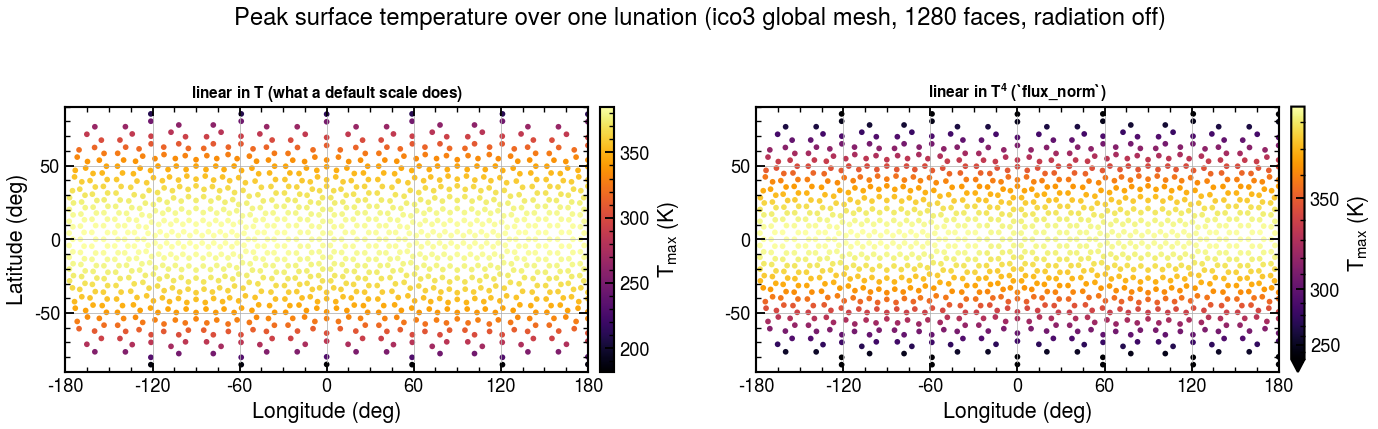

In [9]:
norm_tmax = flux_norm(tmax)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, norm, label in ((axes[0], Normalize(tmax.min(), tmax.max()),
                         "linear in $T$ (what a default scale does)"),
                        (axes[1], norm_tmax, "linear in $T^4$ (`flux_norm`)")):
    sc = ax.scatter(lon, lat, c=tmax, cmap=CMAP_T, norm=norm, s=14, linewidths=0)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_xlabel("Longitude (deg)")
    ax.set_title(label, fontsize=10)
    ax.grid(True, linewidth=0.5)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, extend=clip_extend(tmax, norm))
    cb.set_label(r"$T_\mathrm{max}$ (K)")
axes[0].set_ylabel("Latitude (deg)")
fig.suptitle(f"Peak surface temperature over one lunation "
             f"(ico3 global mesh, {run.n_faces} faces, radiation off)", y=1.02)
plt.tight_layout()
plt.show()

Equatorial face: index 256, lat=0.00 deg, lon=126.00 deg


240 output steps spanning 707.2 h (29.5 d); cadence 2.96 h/step
face 256 curve: min=94.1 K, max=384.5 K


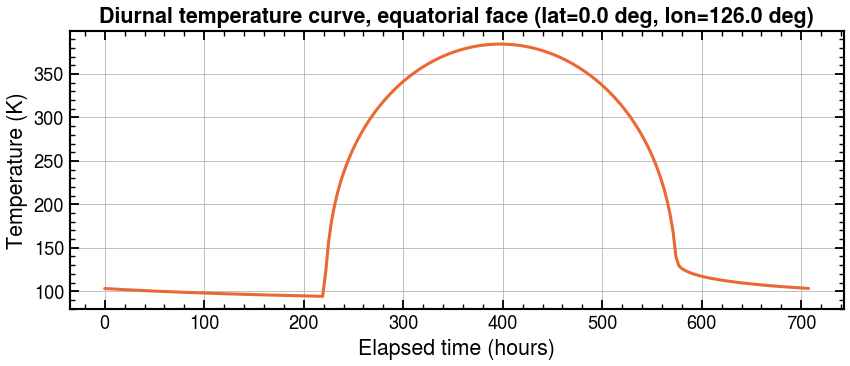

In [10]:
# Pick one equatorial face deterministically (nearest to lat=0). Results also
# selects by position -- run.face_at(lat=..., lon=...) -- which exercise 3 uses.
eq_face = int(np.argmin(np.abs(lat)))
print(f"Equatorial face: index {eq_face}, lat={lat[eq_face]:.2f} deg, "
      f"lon={lon[eq_face]:.2f} deg")

# series() reads the 240 per-step files and returns elapsed hours with them.
# Column 1 of time_steps.txt is seconds past J2000 (SPICE ET), not elapsed time
# despite the file's own header comment; series() rebases it.
t_hr, curve = run.series("temperature", face=eq_face)
utc_labels = run.times().utc
print(f"{len(t_hr)} output steps spanning {t_hr[-1]:.1f} h "
      f"({t_hr[-1]/24:.1f} d); cadence {np.median(np.diff(t_hr)):.2f} h/step")
print(f"face {eq_face} curve: min={curve.min():.1f} K, max={curve.max():.1f} K")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(t_hr, curve, color=ACCENT_ORANGE, linewidth=2)
ax.set_xlabel("Elapsed time (hours)")
ax.set_ylabel("Temperature (K)")
ax.set_title(f"Diurnal temperature curve, equatorial face "
             f"(lat={lat[eq_face]:.1f} deg, lon={lon[eq_face]:.1f} deg)")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()

day/night contrast (Tmax-Tmin): min=115.6  max=290.7  mean=264.9 K  (n_distinct@0.1K=526, range=175.2 K)
correlation with |latitude|: r = -0.92


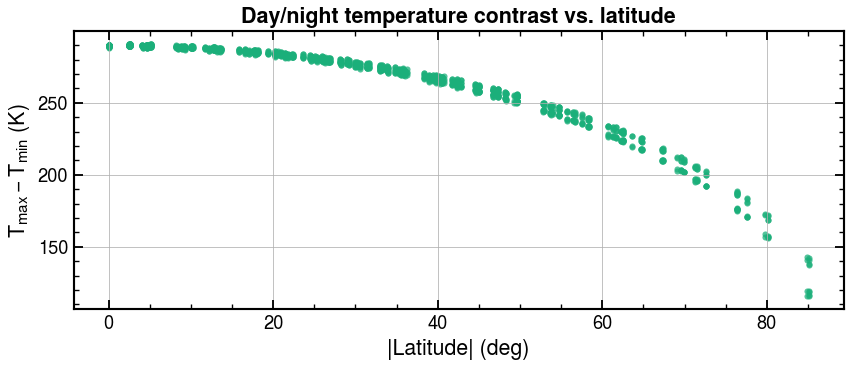

In [11]:
contrast = tmax - tmin
n_distinct_contrast = len(np.unique(np.round(contrast, 1)))
corr = float(np.corrcoef(np.abs(lat), contrast)[0, 1])
print(f"day/night contrast (Tmax-Tmin): min={contrast.min():.1f}  "
      f"max={contrast.max():.1f}  mean={contrast.mean():.1f} K  "
      f"(n_distinct@0.1K={n_distinct_contrast}, "
      f"range={contrast.max()-contrast.min():.1f} K)")
print(f"correlation with |latitude|: r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(np.abs(lat), contrast, color=ACCENT_AQUA, s=16, alpha=0.75, linewidths=0)
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Day/night temperature contrast vs. latitude")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()

### 4.4 Globe views

The lat/lon scatter is an equirectangular projection: it stretches the poles
across the full width of the plot and cuts the body open at ±180°.
Orthographic globes show the field as a distant camera would see it — no
distortion at the center of the disk, each pole in a panel of its own, and no
seam.

`run.plot_globes()` draws them with matplotlib alone. It averages the
per-face temperatures onto the mesh vertices, projects the vertices
orthographically for each viewpoint, keeps the triangles whose three vertices
all face the viewer, and lets `tripcolor(..., shading="gouraud")` interpolate
linearly across each triangle. Nothing is resampled onto a raster grid, so
the picture is the mesh's own field, smoothed only by that interpolation. A
30° graticule gives the orientation. The renderer underneath,
`ptm.plots.globe(ax, ...)`, takes a single axes, and is what section 6
composes by hand into a two-row polar figure.

vertex field: 642 vertices, 184.9-384.9 K (faces 182.0-385.0 K -- averaging onto vertices clips the extremes slightly, as it should)


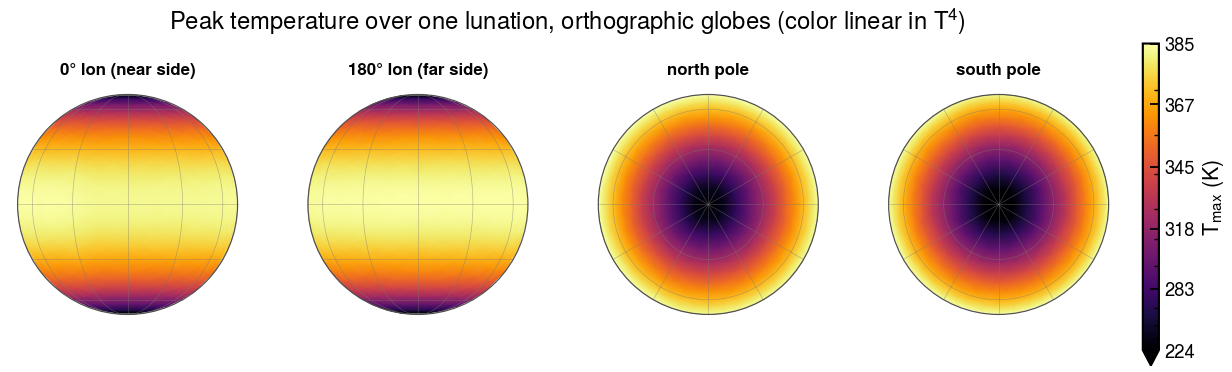

In [12]:
VIEWS = [(0.0, 0.0, "0° lon (near side)"),
         (0.0, 180.0, "180° lon (far side)"),
         (90.0, 0.0, "north pole"),
         (-90.0, 0.0, "south pole")]

tmax_vertex = plots.vertex_values_from_faces(run.mesh["faces"], tmax,
                                             run.mesh["n_vertices"])
print(f"vertex field: {run.mesh['n_vertices']} vertices, "
      f"{tmax_vertex.min():.1f}-{tmax_vertex.max():.1f} K "
      f"(faces {tmax.min():.1f}-{tmax.max():.1f} K -- averaging onto vertices "
      "clips the extremes slightly, as it should)")

fig = run.plot_globes("temperature", "max", views=VIEWS,
                      label=r"$T_\mathrm{max}$ (K)")
fig.suptitle("Peak temperature over one lunation, orthographic globes "
             "(color linear in $T^4$)", y=0.97)
plt.show()

#### An instantaneous snapshot, seen from the Sun and from the night side

The globes above show a *statistic* accumulated over the whole lunation. A
single output step is a different kind of field: a hot day side and a cold
night side separated by a terminator, spanning the full temperature range with
a large population at each end. That field is not compressed, so it takes a
plain linear scale — the choice depends on the distribution, not on habit.

The sub-solar point comes from `body_positions.csv`, which records the Sun
vector in the body-fixed frame at every output step, so recovering it is a
coordinate conversion and not an inference. The cell checks it against the
single brightest face of the `direct_solar` field.

step 120 (2026-04-19T20:34:32.927): sub-solar point at lat +1.2, lon +147.4 deg
  brightest face is 3.6 deg away (mesh face pitch is ~5.7 deg -- agreement to within one face is the expected result)
  snapshot temperature range 66.8-384.5 K; 50% of faces are lit


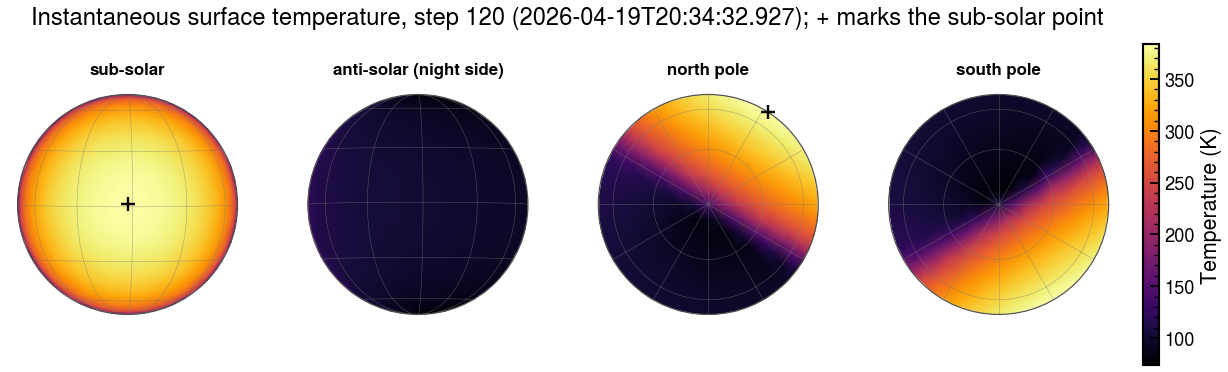

In [13]:
SNAP_STEP = len(run.times().et) // 2
T_snap = run.field("temperature", SNAP_STEP)
ds_snap = run.field("direct_solar", SNAP_STEP)

sub_lat, sub_lon = run.subsolar_latlon(SNAP_STEP)
brightest = int(np.argmax(ds_snap))
sub_vec = plots.face_unit_vectors(np.array([sub_lat]), np.array([sub_lon]))[0]
sep_deg = np.degrees(np.arccos(np.clip(
    run.face_unit_vectors[brightest] @ sub_vec, -1, 1)))
print(f"step {SNAP_STEP} ({utc_labels[SNAP_STEP]}): sub-solar point at "
      f"lat {sub_lat:+.1f}, lon {sub_lon:+.1f} deg")
print(f"  brightest face is {sep_deg:.1f} deg away (mesh face pitch is "
      f"~{np.degrees(np.sqrt(4 * np.pi / run.n_faces)):.1f} deg -- agreement to "
      "within one face is the expected result)")
print(f"  snapshot temperature range {T_snap.min():.1f}-{T_snap.max():.1f} K; "
      f"{100 * np.mean(ds_snap > 0):.0f}% of faces are lit")

SNAP_VIEWS = [(sub_lat, sub_lon, "sub-solar"),
              (-sub_lat, sub_lon + 180.0, "anti-solar (night side)"),
              (90.0, 0.0, "north pole"),
              (-90.0, 0.0, "south pole")]

fig = run.plot_globes("temperature", step=SNAP_STEP, views=SNAP_VIEWS,
                      flux_scaled=False, mark_subsolar=True,
                      label="Temperature (K)")
fig.suptitle(f"Instantaneous surface temperature, step {SNAP_STEP} "
             f"({utc_labels[SNAP_STEP]}); + marks the sub-solar point", y=0.97)
plt.show()

## 5. Interpretation

**The diurnal wave.** The equatorial face's curve traces one full lunar day:
a slow ~350-hour rise to noon as the Sun climbs (the ~3 h output cadence
oversamples this comfortably relative to the ~709 h lunation), then an even
slower fall. Peak temperature and peak insolation land in the *same* output
step for this face — the true lag between them is shorter than the ~3 h
sampling interval, so it is not resolved here (Exercise 2 shows how to
resolve it).

**Thermal inertia** shows most clearly in the shape of the night side.
Insolation drops to zero at sunset in a single step (a geometric on/off), but
temperature does not follow it down: the surface cools quickly for the first
hour or two (radiating away the shallow layer's heat), then the cooling rate
drops sharply and the temperature glides down almost linearly for the rest of
the ~450-hour lunar night, bottoming out just before sunrise. The slow glide
is heat conducted up from the deeper, still-warm regolith layers, arriving at
the surface with a delay set by the thermal skin depth — the thermal-inertia
concept from `docs/tutorials/02_lunar_diurnal_icosphere.md` and the classic
Diviner nighttime-plateau observation it cites.

**Day/night contrast vs. latitude.** The scatter is close to a clean,
monotonically decreasing trend (correlation printed above, typically around
$r\approx-0.9$): near the equator the Sun reaches near-normal incidence at
noon (`temperature_max` close to the sub-solar blackbody limit) while the
nighttime floor is the same ~90-95 K everywhere, so the swing is largest
there. Toward the poles, grazing incidence caps `temperature_max` well below
the equatorial value while `temperature_min` drops only modestly, so the
swing narrows. This geometry is why polar regions are cold-trap territory
even before topographic shadowing — which tutorial 04's crater case adds — is
in play.


**What the globes add.** The equirectangular map and the globes hold the same
numbers, but the globes make two things obvious that the scatter hides. First,
the polar panels show that the cold cap is a genuinely small piece of the
Moon: stretched across the top of an equirectangular plot it looks like a
major province, while on the globe it is a thumbprint. Second, the near-side
and far-side panels are the same to the eye — as they must be on a smooth
sphere with uniform properties, where nothing distinguishes one longitude from
another. That is a useful null: any longitude structure appearing in these two
panels in a later run comes from something the model added, whether topography
(section 6), an albedo map, or an incompletely equilibrated start.

## 6. The same run on real lunar topography

Everything above sits on a perfect sphere. PTM3D can instead displace every
mesh vertex to the real lunar radius from an LRO LOLA topography grid, which
tilts each face by the local slope and changes the incidence angle the solar
beam sees. This section runs that comparison at res-5 (20,480 faces) and
isolates the effect of the topography alone.

The grids ship in the project's data distribution, not in git:

```bash
python3 scripts/fetch_data.py --dataset moon-topo          # ico3-ico9, LOLA-derived
python3 scripts/fetch_data.py --core                       # + property and albedo maps
```

`fetch_data.py --list` shows the catalog, and `data/README.md` records the
provenance and licenses. A relative `data/...` path in a config resolves
against `$PTM_DATA_ROOT` first if that variable is set, otherwise against the
repository's own `data/` directory.

Two configs make the comparison, differing in exactly one physics key:

| | `examples/moon_global_topo_res5.yaml` | `examples/moon_global_topo_res5_flat.yaml` |
|---|---|---|
| `mesh.use_topographic` | `true` | `false` |
| everything else | res-5 icosphere, 29.53 d, 240 steps, LOLA albedo map, Diviner H-parameter map | identical |

Because the face count and connectivity are the same in both runs, the two
outputs can be differenced face by face.

In [14]:
TOPO_CONFIG = REPO_ROOT / "examples" / "moon_global_topo_res5.yaml"
FLAT_CONFIG = REPO_ROOT / "examples" / "moon_global_topo_res5_flat.yaml"
TOPO_GRID = REPO_ROOT / "data" / "topo" / "moon" / "topo_moon_ico5.bin"

for path in (TOPO_CONFIG, FLAT_CONFIG):
    if not path.exists():
        raise FileNotFoundError(f"{path} is missing from this checkout")
if not TOPO_GRID.exists():
    raise FileNotFoundError(
        f"{TOPO_GRID} not found. Fetch the topography dataset first:\n"
        "    python3 scripts/fetch_data.py --dataset moon-topo")

WATCH = ("Loading topographic mesh", "Mesh created with", "[property-map]",
         "Albedo range:", "Simulation completed in")
_, t_topo = run_engine(TOPO_CONFIG, stream=False, show=WATCH)
_, t_flat = run_engine(FLAT_CONFIG, stream=False, show=WATCH)
print(f"\nres-5 pair: {t_topo:.1f} s + {t_flat:.1f} s = {t_topo + t_flat:.1f} s total")

Running: /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-ux5a/examples/moon_global_topo_res5.yaml 
(cwd=/Users/paha3326/Projects/ptm-ux5a)



    Mesh created with 10242 vertices and 20480 faces
    Loading topographic mesh from: data/topo/moon/topo_moon_ico5.bin
    [property-map] H_PARAMETER (bundled default)  source=data/property_maps/moon/hpar_moon_ico5.bin  faces=20480  default_fraction=5.89844%  H[range]=0.06..0.0852979 m
    Albedo range: 0.069 to 0.218
    Albedo range: 0.069 to 0.218
    Simulation completed in 9.395 seconds (9395 ms)
    -> exit 0 in 9.8 s
Running: /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-ux5a/examples/moon_global_topo_res5_flat.yaml 
(cwd=/Users/paha3326/Projects/ptm-ux5a)



    Mesh created with 10242 vertices and 20480 faces
    Mesh created with 10242 vertices and 20480 faces
    [property-map] H_PARAMETER (bundled default)  source=data/property_maps/moon/hpar_moon_ico5.bin  faces=20480  default_fraction=5.89844%  H[range]=0.06..0.0852979 m
    Albedo range: 0.069 to 0.218
    Albedo range: 0.069 to 0.218
    Simulation completed in 9.241 seconds (9241 ms)
    -> exit 0 in 9.6 s

res-5 pair: 9.8 s + 9.6 s = 19.3 s total


In [15]:
topo = Results(REPO_ROOT / "output" / "moon_global_topo_res5")
flat = Results(REPO_ROOT / "output" / "moon_global_topo_res5_flat")
lat_t, lon_t = topo.lat, topo.lon

# The two meshes must be the same triangulation for a face-by-face difference.
if not np.array_equal(topo.mesh["faces"], flat.mesh["faces"]):
    raise ValueError("the two runs used different triangulations -- "
                     "cannot difference them")
print(f"same triangulation ({topo.n_faces} faces); largest per-face latitude "
      f"shift between the two meshes: {np.abs(lat_t - flat.lat).max():.4f} deg")
print(f"mesh.ply length unit: topographic run {topo.mesh_units}, smooth run "
      f"{flat.mesh_units} -- the file records neither, so Results settles it "
      "the way the engine does")

# Relief, as a radius anomaly about the mesh's own median radius.
R_MOON_KM = 1737.4
r_topo = np.linalg.norm(topo.mesh["vertices"], axis=1)
relief_km = (r_topo / np.median(r_topo) - 1.0) * R_MOON_KM
relief_face = relief_km[topo.mesh["faces"]].mean(axis=1)
print(f"LOLA relief at res-5: {relief_km.min():+.1f} to {relief_km.max():+.1f} km "
      f"about the mean radius (RMS {relief_km.std():.2f} km)")

topo_tmax = topo.stat("temperature", "max")
flat_tmax = flat.stat("temperature", "max")
d_tmax = topo_tmax - flat_tmax
d_tmin = topo.stat("temperature", "min") - flat.stat("temperature", "min")

print(f"\nTmax  topo {topo_tmax.min():.1f}-{topo_tmax.max():.1f} K   "
      f"flat {flat_tmax.min():.1f}-{flat_tmax.max():.1f} K")
print(f"  difference (topo - flat): mean {d_tmax.mean():+.2f} K, "
      f"RMS {d_tmax.std():.2f} K, range {d_tmax.min():+.1f} to {d_tmax.max():+.1f} K")
print(f"  |difference| > 5 K on {100 * np.mean(np.abs(d_tmax) > 5):.1f}% of faces")
print(f"Tmin  difference: mean {d_tmin.mean():+.2f} K, RMS {d_tmin.std():.2f} K, "
      f"range {d_tmin.min():+.1f} to {d_tmin.max():+.1f} K")

same triangulation (20480 faces); largest per-face latitude shift between the two meshes: 0.0019 deg
mesh.ply length unit: topographic run m, smooth run km -- the file records neither, so Results settles it the way the engine does
LOLA relief at res-5: -6.8 to +9.6 km about the mean radius (RMS 2.34 km)

Tmax  topo 79.4-390.1 K   flat 59.8-390.0 K
  difference (topo - flat): mean -0.01 K, RMS 3.38 K, range -71.4 to +105.3 K
  |difference| > 5 K on 5.5% of faces
Tmin  difference: mean -0.02 K, RMS 0.27 K, range -19.0 to +6.4 K


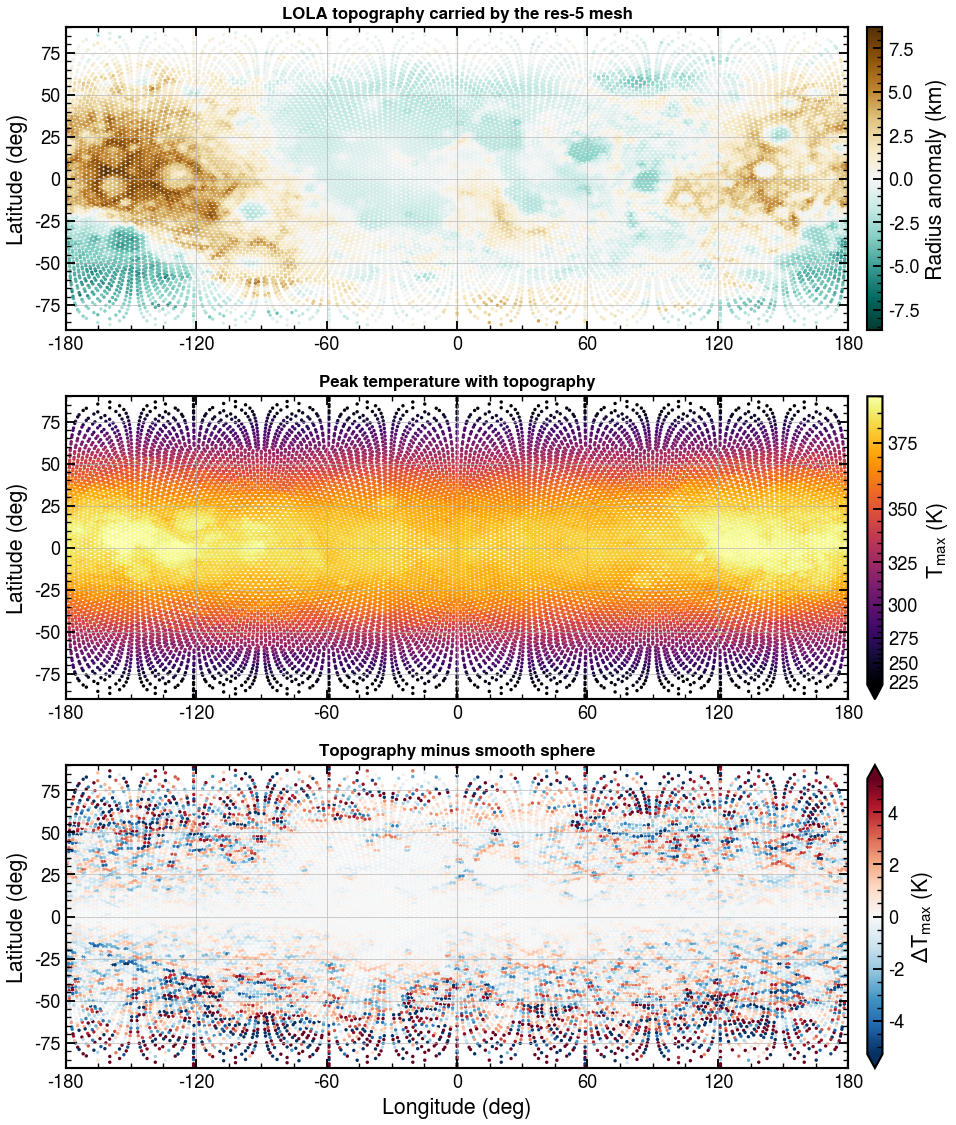

In [16]:
norm_topo_tmax = flux_norm(topo_tmax)
norm_relief = sym_norm(relief_face, pct=100.0)
# The topographic change is concentrated at high latitude, so clip the color
# limits at the 95th percentile of |change| and let the colorbar arrows say so.
norm_dtmax = sym_norm(d_tmax, pct=95.0)

fig, axes = plt.subplots(3, 1, figsize=(9.5, 10.5))
panels = [
    (relief_face, "BrBG_r", norm_relief, "Radius anomaly (km)",
     "LOLA topography carried by the res-5 mesh"),
    (topo_tmax, CMAP_T, norm_topo_tmax, r"$T_\mathrm{max}$ (K)",
     "Peak temperature with topography"),
    (d_tmax, CMAP_DIFF, norm_dtmax, r"$\Delta T_\mathrm{max}$ (K)",
     "Topography minus smooth sphere"),
]
for ax, (values, cmap, norm, cblabel, title) in zip(axes, panels):
    sc = ax.scatter(lon_t, lat_t, c=values, cmap=cmap, norm=norm, s=5, linewidths=0)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_ylabel("Latitude (deg)")
    ax.set_title(title, fontsize=11)
    ax.grid(True, linewidth=0.4)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, extend=clip_extend(values, norm))
    cb.set_label(cblabel)
axes[-1].set_xlabel("Longitude (deg)")
plt.tight_layout()
plt.show()

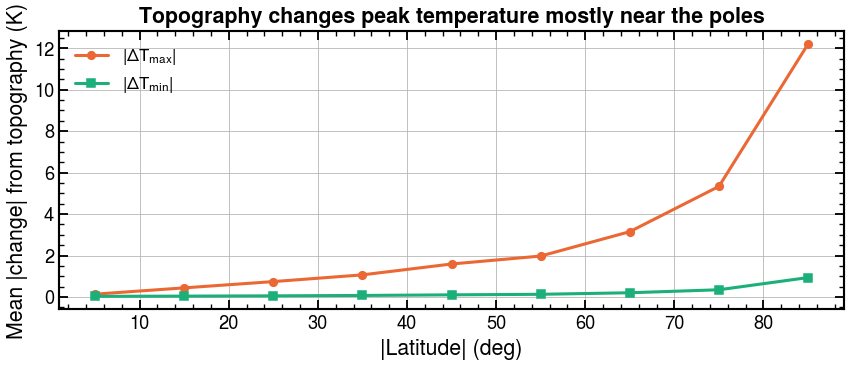

  |lat|  0-10 deg : mean |dTmax| =  0.14 K
  |lat| 10-20 deg : mean |dTmax| =  0.44 K
  |lat| 20-30 deg : mean |dTmax| =  0.74 K
  |lat| 30-40 deg : mean |dTmax| =  1.07 K
  |lat| 40-50 deg : mean |dTmax| =  1.59 K
  |lat| 50-60 deg : mean |dTmax| =  1.97 K
  |lat| 60-70 deg : mean |dTmax| =  3.15 K
  |lat| 70-80 deg : mean |dTmax| =  5.33 K
  |lat| 80-90 deg : mean |dTmax| = 12.20 K


In [17]:
# Where does topography matter? Bin the absolute change by latitude.
edges = np.arange(0, 91, 10)
abs_lat = np.abs(lat_t)
centers_lat = 0.5 * (edges[:-1] + edges[1:])
mean_abs = np.array([np.abs(d_tmax[(abs_lat >= a) & (abs_lat < b)]).mean()
                     for a, b in zip(edges[:-1], edges[1:])])
mean_abs_min = np.array([np.abs(d_tmin[(abs_lat >= a) & (abs_lat < b)]).mean()
                         for a, b in zip(edges[:-1], edges[1:])])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(centers_lat, mean_abs, "o-", color=ACCENT_ORANGE, lw=2,
        label=r"$|\Delta T_\mathrm{max}|$")
ax.plot(centers_lat, mean_abs_min, "s-", color=ACCENT_AQUA, lw=2,
        label=r"$|\Delta T_\mathrm{min}|$")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel("Mean |change| from topography (K)")
ax.set_title("Topography changes peak temperature mostly near the poles")
ax.grid(True, linewidth=0.5)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

for a, b, v in zip(edges[:-1], edges[1:], mean_abs):
    print(f"  |lat| {a:2d}-{b:2d} deg : mean |dTmax| = {v:5.2f} K")

The globes below put the same difference field on the two poles, where it is
largest, next to the peak-temperature field itself.

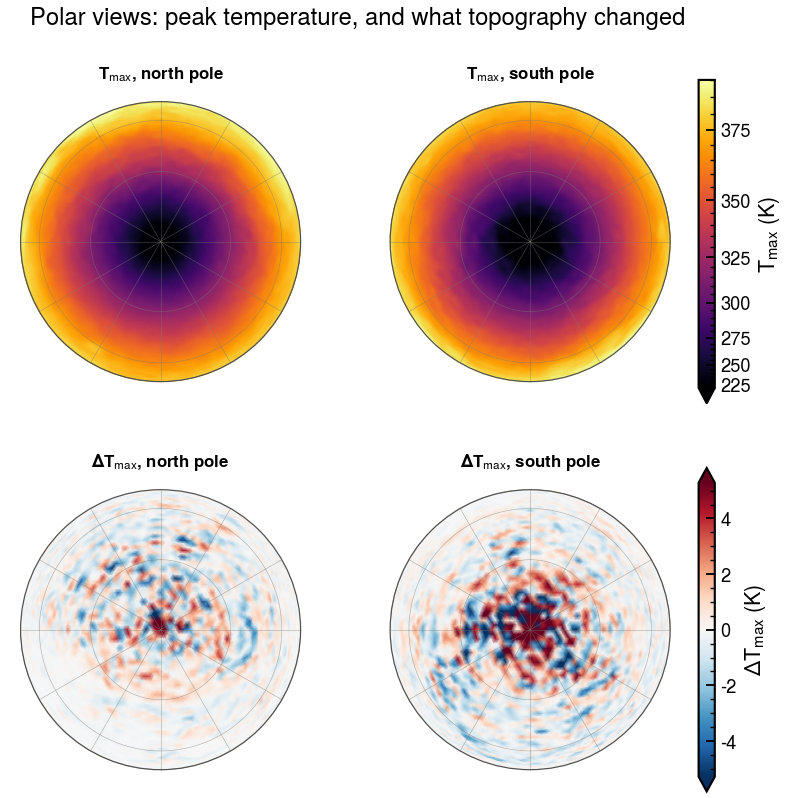

In [18]:
mesh_t = topo.mesh
tmax_v = plots.vertex_values_from_faces(mesh_t["faces"], topo_tmax,
                                        mesh_t["n_vertices"])
dtmax_v = plots.vertex_values_from_faces(mesh_t["faces"], d_tmax,
                                         mesh_t["n_vertices"])

fig, axes = plt.subplots(2, 2, figsize=(8.5, 8.4))
panels = [(axes[0][0], tmax_v, 90.0, CMAP_T, norm_topo_tmax,
           r"$T_\mathrm{max}$, north pole"),
          (axes[0][1], tmax_v, -90.0, CMAP_T, norm_topo_tmax,
           r"$T_\mathrm{max}$, south pole"),
          (axes[1][0], dtmax_v, 90.0, CMAP_DIFF, norm_dtmax,
           r"$\Delta T_\mathrm{max}$, north pole"),
          (axes[1][1], dtmax_v, -90.0, CMAP_DIFF, norm_dtmax,
           r"$\Delta T_\mathrm{max}$, south pole")]
art = {}
for ax, values, view_lat, cmap, norm, title in panels:
    art[view_lat > 0, cmap] = plots.globe(
        ax, mesh_t["vertices"], mesh_t["faces"], values, view_lat, 0.0,
        cmap=cmap, norm=norm, title=title)
cb0 = fig.colorbar(art[True, CMAP_T], ax=axes[0], fraction=0.045, pad=0.02,
                   extend=clip_extend(tmax_v, norm_topo_tmax))
cb0.set_label(r"$T_\mathrm{max}$ (K)")
cb2 = fig.colorbar(art[True, CMAP_DIFF], ax=axes[1], fraction=0.045, pad=0.02,
                   extend=clip_extend(dtmax_v, norm_dtmax))
cb2.set_label(r"$\Delta T_\mathrm{max}$ (K)")
fig.suptitle("Polar views: peak temperature, and what topography changed", y=0.96)
plt.show()

### What the topography run shows

**The mean is not the story.** Averaged over the Moon, topography changes
$T_\mathrm{max}$ by essentially nothing — printed above as a mean near zero.
That is expected: a slope tilted toward the Sun at noon is matched somewhere
else by one tilted away, and the two cancel in the mean. The *spread* is what
matters, and it is not small: several kelvin RMS, with the extreme faces moving
by tens of kelvin.

**The effect is a polar effect.** The binned curve rises steeply with latitude.
The reason is the same quarter-power law that motivated the color scale: with
the Sun near the zenith, tilting a face by a degree changes $\cos i$ by
almost nothing, so the temperature barely moves; with the Sun a few degrees
above the horizon, the same one-degree tilt is a large *fractional* change in
$\cos i$, and near-grazing faces can swing by tens of kelvin. Polar
thermal modeling is therefore topography modeling, which is why the
crater-scale tutorials use real DEM meshes rather than global icospheres.

**Night temperatures barely notice.** The change in $T_\mathrm{min}$ is an
order of magnitude smaller than in $T_\mathrm{max}$. After sunset the surface
has no illumination geometry left to care about: the nighttime floor is set by
how much heat the regolith stored and how fast it conducts, and a slope changes
neither.

**What this section does not cover.** Both arms carry the same LOLA albedo map
and Diviner H-parameter map, so the difference is attributable to the geometry
alone — but only at res-5, where a face spans roughly 250 km and the mesh
resolves the great basins rather than craters. It captures none of the
shadowing that makes real polar craters cold traps: a res-5 face is far larger
than any crater, and this configuration has `radiation.enabled: false`, so no
face casts a shadow on another. For that physics, see the crater tutorial with
its DEM mesh and radiation exchange.

## 7. Exercises

1. **Sharper map, config change only.** Copy
   `examples/quickstart_moon_diurnal.yaml`, bump `mesh.resolution: 3` to
   `4` (1280 → 5120 faces, ~240 km pitch), and re-run section 2 against the
   new config/output directory. Still comfortably laptop-sized —
   `scripts/ptm_mem_estimate.py --faces 5120 --steps 240` gives the estimate.
   Re-run the temperature-map plot on the new output and compare the
   blockiness.

2. **Resolve the noon lag.** Peak insolation and peak temperature land in the
   *same* ~3 h output step above — the true thermal lag is shorter than that.
   Bump `simulation.timesteps` from `240` to `960` (~45 min/step; wall time
   and output size scale roughly with it) and re-run the "diurnal curve"
   cell's flux-vs-temperature comparison for the same equatorial face to see
   whether the peaks separate.

3. **Poles vs. equator, no re-run needed.** Everything after section 3 reads
   from the same `Results` object, which selects a face by position. Ask it
   for a polar one instead of the equatorial one — `run.plot_diurnal(lat=85,
   lon=0)` is the whole change — and compare. Expect a much smaller swing
   (consistent with the day/night contrast plot) and a flatter shape —
   grazing incidence spreads a weaker flux over more of the "day."

4. **Resolve the topography.** Section 6 runs at res-5, where one face
   spans about 250 km. Copy both configs, set `mesh.resolution: 6`
   (81,920 faces; `topo_moon_ico6.bin` comes with the same dataset) and
   re-run the pair. Check `scripts/ptm_mem_estimate.py --faces 81920
   --steps 240` first. The mean change should stay near zero while the
   RMS grows, because a finer mesh resolves steeper slopes.

**Note on thermophysical exercises:** `body: Moon` is a *built-in* body, and
plain-named thermophysical properties (`H`, `ks`, `kd`, `rhos`, `rhod`,
`albedo`, ...) in a config are not read on a named body — only
`use_default_albedo`, `incidence_angle_albedo`, and the
`*_override`/`*_model` keys are (see
[`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md)), and there is no
config route to a non-default scalar `H` on a named body except
`h_parameter_map` (a per-face raster). A scalar-`H` sweep needs a custom
`generic_body:` block instead (e.g.
[`configs/amundsen_phase2_template.yaml`](../../../configs/amundsen_phase2_template.yaml),
which sets `H: 0.06` under `generic_body.surface:`). The exercises above
therefore vary what the Moon preset does expose (resolution, output cadence)
plus a config-free re-analysis (latitude) that shows the same physics.

## Version

The binary and commit that produced the numbers in this notebook.


In [19]:
import hashlib
import subprocess


def git(*args):
    return subprocess.run(("git",) + args, cwd=str(REPO_ROOT), check=True,
                          capture_output=True, text=True).stdout.strip()


print("Binary:", BINARY)
print("MD5:   ", hashlib.md5(BINARY.read_bytes()).hexdigest())
try:
    print("Commit:", git("rev-parse", "HEAD"),
          f"({git('rev-parse', '--abbrev-ref', 'HEAD')})")
except (OSError, subprocess.CalledProcessError) as exc:
    print("(git information unavailable in this environment:", exc, ")")

print(f"\nWall time of the run in section 2: {wall_time_s:.1f} s")

Binary: /Users/paha3326/Projects/ptm-ux5a/build/bin/ptm_thermal_sim
MD5:    96b7dca84d25df4d31d21e246632fe58
Commit: 83d45f660abb07b9e246025c85c4cb93dfabc543 (docs/tutorials-on-ptm-api)

Wall time of the run in section 2: 6.8 s
